In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("whitegrid")

In [2]:
data=pd.read_csv("clean_diabetic_data.csv")
data

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,unknown,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,unknown,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,unknown,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,unknown,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,443847548,100162476,AfricanAmerican,Male,[70-80),1,3,7,3,unknown,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),1,4,5,5,unknown,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),1,1,7,1,unknown,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),2,3,7,10,Surgery-General,...,No,Up,No,No,No,No,No,Ch,Yes,NO


In [3]:
# Dataset dimensions
print("Rows and Columns:", data.shape)

# First five records
display(data.head())

# Dataset information
data.info()

# Duplicate records
print("Duplicates:", data.duplicated().sum())

# Readmission distribution
print(data['readmitted'].value_counts())

Rows and Columns: (101766, 47)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,unknown,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,unknown,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,unknown,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,unknown,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 47 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101763 non-null  object
 4   age                       101766 non-null  object
 5   admission_type_id         101766 non-null  int64 
 6   discharge_disposition_id  101766 non-null  int64 
 7   admission_source_id       101766 non-null  int64 
 8   time_in_hospital          101766 non-null  int64 
 9   medical_specialty         101766 non-null  object
 10  num_lab_procedures        101766 non-null  int64 
 11  num_procedures            101766 non-null  int64 
 12  num_medications           101766 non-null  int64 
 13  number_outpatient         101766 non-null  int64 
 14  numb

In [4]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


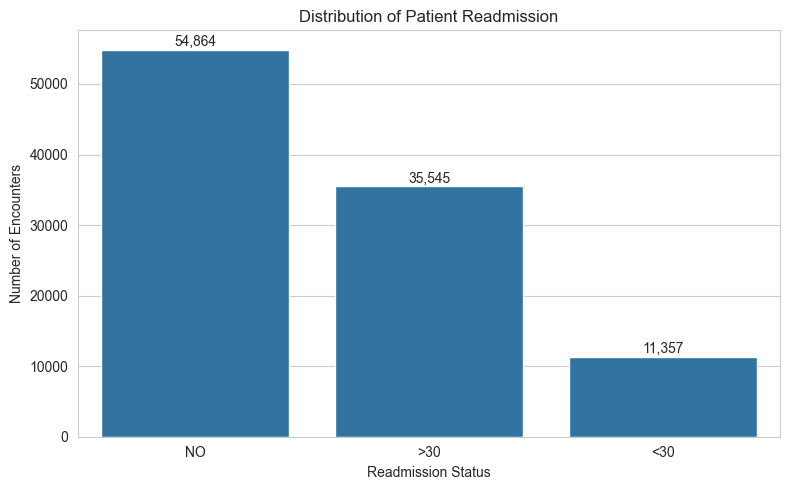

In [6]:
#Readmission distribution

readmission_counts = data['readmitted'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=readmission_counts.index,
    y=readmission_counts.values
)

plt.title('Distribution of Patient Readmission')
plt.xlabel('Readmission Status')
plt.ylabel('Number of Encounters')

for i, value in enumerate(readmission_counts.values):
    plt.text(i, value + 500, f'{value:,}', ha='center')

plt.tight_layout()
plt.show()


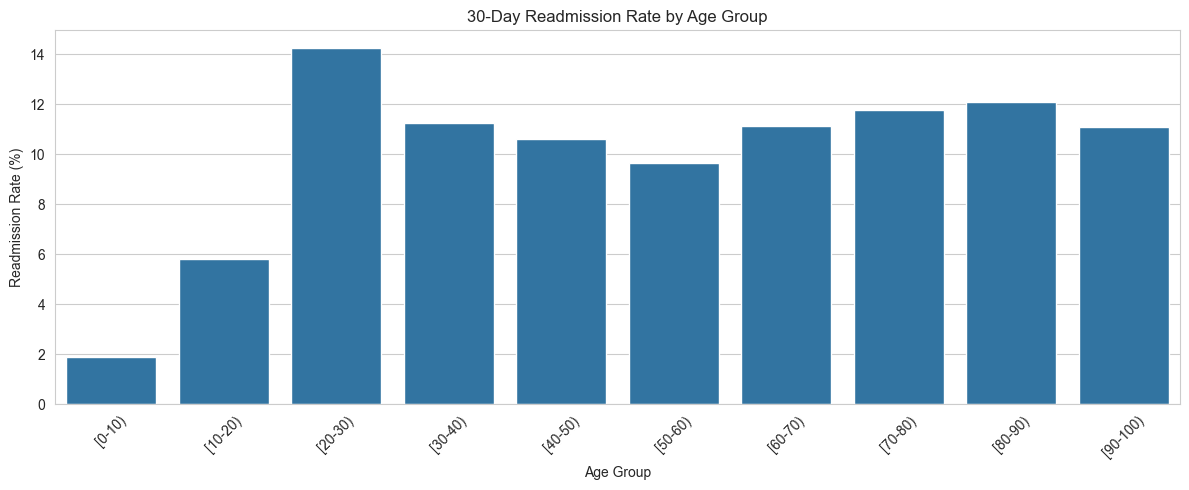

In [7]:
##Readmission by age group

age_readmission = (
    data.groupby('age')['readmitted']
    .apply(lambda x: (x == '<30').mean() * 100)
    .reset_index(name='Readmission_Rate')
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=age_readmission,
    x='age',
    y='Readmission_Rate'
)

plt.title('30-Day Readmission Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Readmission Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

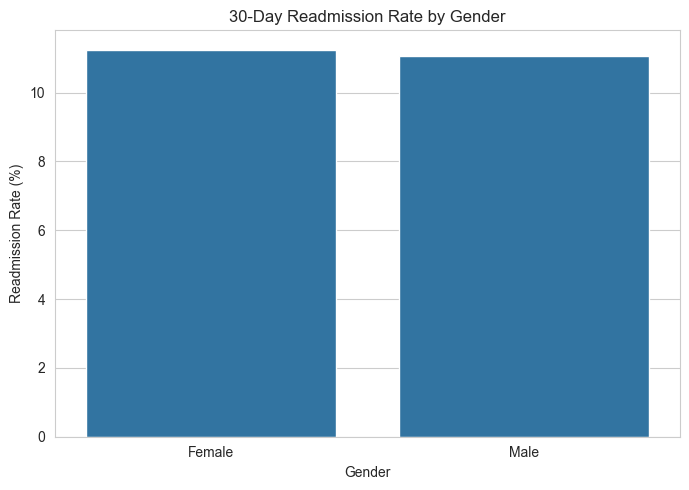

In [8]:
##Readmission by gender

gender_readmission = (
    data.groupby('gender')['readmitted']
    .apply(lambda x: (x == '<30').mean() * 100)
    .reset_index(name='Readmission_Rate')
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=gender_readmission,
    x='gender',
    y='Readmission_Rate'
)

plt.title('30-Day Readmission Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Readmission Rate (%)')

plt.tight_layout()
plt.show()

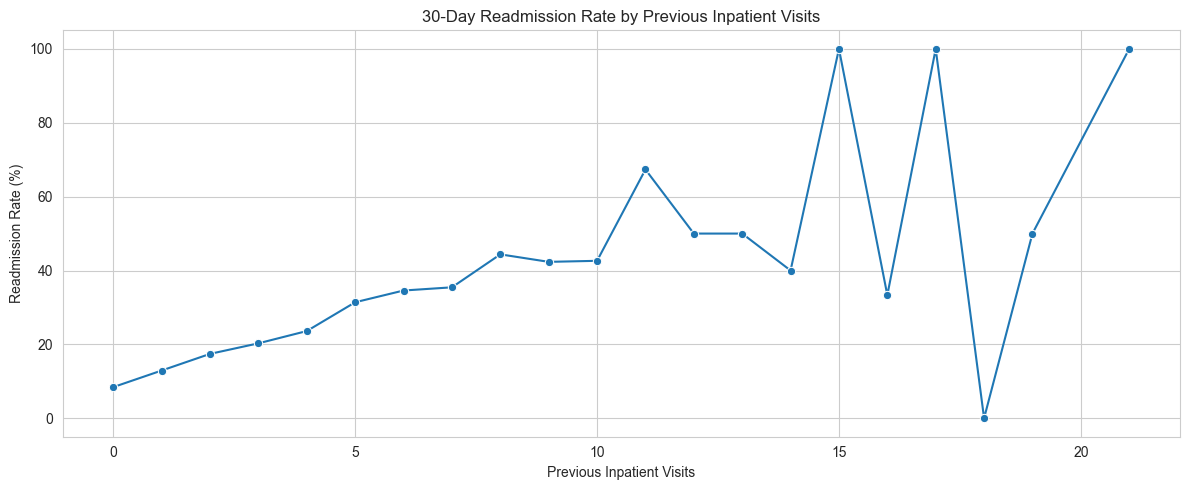

In [9]:
##Readmission by previous inpatient visits
inpatient_readmission = (
    data.groupby('number_inpatient')['readmitted']
    .apply(lambda x: (x == '<30').mean() * 100)
    .reset_index(name='Readmission_Rate')
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=inpatient_readmission,
    x='number_inpatient',
    y='Readmission_Rate',
    marker='o'
)

plt.title('30-Day Readmission Rate by Previous Inpatient Visits')
plt.xlabel('Previous Inpatient Visits')
plt.ylabel('Readmission Rate (%)')

plt.tight_layout()
plt.show()

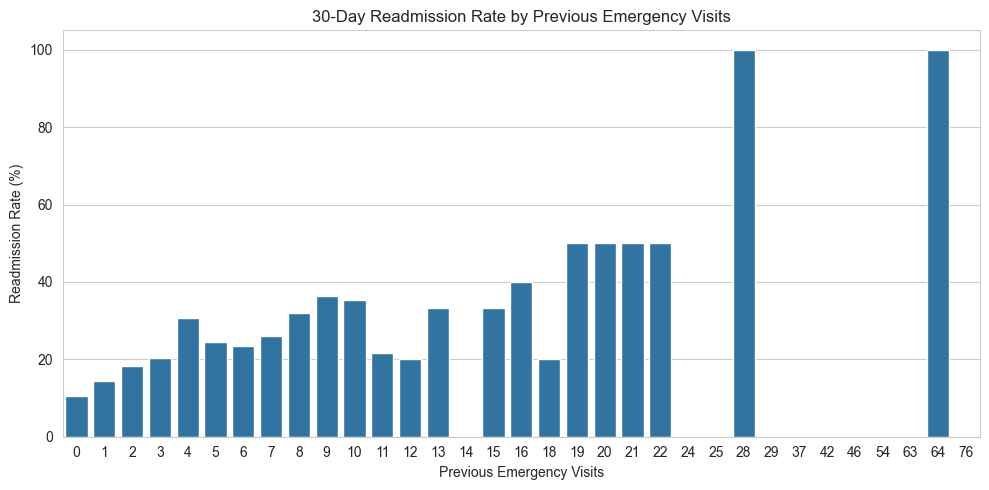

In [10]:
##Readmission by previous emergency visits
emergency_readmission = (
    data.groupby('number_emergency')['readmitted']
    .apply(lambda x: (x == '<30').mean() * 100)
    .reset_index(name='Readmission_Rate')
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=emergency_readmission,
    x='number_emergency',
    y='Readmission_Rate'
)

plt.title('30-Day Readmission Rate by Previous Emergency Visits')
plt.xlabel('Previous Emergency Visits')
plt.ylabel('Readmission Rate (%)')

plt.tight_layout()
plt.show()

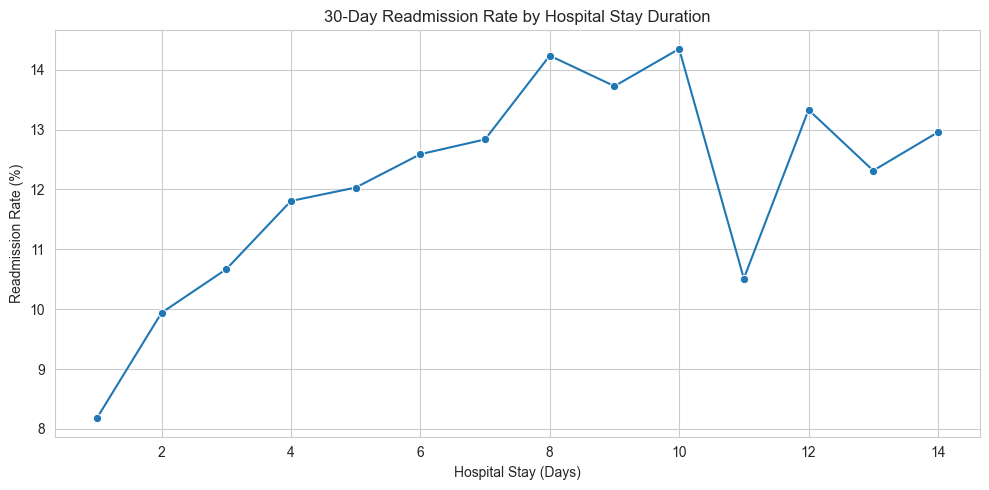

In [11]:
##Readmission by hospital stay duration
stay_readmission = (
    data.groupby('time_in_hospital')['readmitted']
    .apply(lambda x: (x == '<30').mean() * 100)
    .reset_index(name='Readmission_Rate')
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=stay_readmission,
    x='time_in_hospital',
    y='Readmission_Rate',
    marker='o'
)

plt.title('30-Day Readmission Rate by Hospital Stay Duration')
plt.xlabel('Hospital Stay (Days)')
plt.ylabel('Readmission Rate (%)')

plt.tight_layout()
plt.show()